## Credit Risk: Feature Distributions and Insights
- **Session 2 assignment | EDA**
- **Mehrdad Mohammadian**

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

In [4]:
data = pd.read_csv(
    "../1.give_me_some_credit/GiveMeSomeCredit.csv", encoding="latin1")
print(f"Shape: {len(data):,} rows x {data.shape[1]} columns")
data.head()

Shape: 149,724 rows x 14 columns


,SeriousDlqin,RevolvingUtilizationOfUnsecuredLines,age,SEX,EDUCATION,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,NumberOfDefault
0,1,0.878881,40,F,3,0,0.605616,12000.0,19,2,3,11,0.0,1
1,0,1.000000,34,F,1,3,2121.000000,0.0,9,0,2,9,2.0,0
2,0,0.470085,59,F,1,5,1.280078,15916.0,34,6,14,8,0.0,0
3,1,0.908082,26,M,3,3,1.444855,6500.0,22,1,4,8,0.0,2
4,1,1.000000,36,M,3,4,0.913676,2200.0,10,1,1,7,1.0,1


### - Checking distribution of the target variable

In [5]:
CLASS_LABELS = {0: "Non-default (0)", 1: "Default (1)"}
TARGET = "SeriousDlqin"
target_summary = (data[TARGET].value_counts().sort_index()
                  .rename_axis("Target").to_frame("Records"))
target_summary["Label"] = target_summary.index.map(CLASS_LABELS)
target_summary["Share_pct"] = target_summary["Records"].div(len(data)).mul(100)
display(target_summary[["Label", "Records", "Share_pct"]])

,Label,Records,Share_pct
Target,,,
0,Non-default (0),139845,93.401859
1,Default (1),9879,6.598141


### - Checking missing data

In [6]:
audit = pd.DataFrame({
    "dtype": data.dtypes.astype(str),
    "missing_n": data.isna().sum(),
    "missing_pct": data.isna().mean().mul(100).round(2),
})

audit

,dtype,missing_n,missing_pct
SeriousDlqin,int64,0,0.00
RevolvingUtilizationOfUnsecuredLines,float64,0,0.00
age,int64,0,0.00
SEX,object,0,0.00
EDUCATION,int64,0,0.00
NumberOfTime30-59DaysPastDueNotWorse,int64,0,0.00
DebtRatio,float64,0,0.00
MonthlyIncome,float64,29607,19.77
NumberOfOpenCreditLinesAndLoans,int64,0,0.00
NumberOfTimes90DaysLate,int64,0,0.00


There is no missing value in our target variable, and `MonthlyIncome` has the highest number of missing values.

### - Removing duplicated rows

In [7]:
print(f"Number of duplicated rows: {data.duplicated().sum():,}")
data[data.duplicated(keep=False)]

Number of duplicated rows: 142


,SeriousDlqin,RevolvingUtilizationOfUnsecuredLines,age,SEX,EDUCATION,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,NumberOfDefault
30045,0,1.0,32,F,3,0,0.0,NaN,0,1,0,0,0.0,0
30050,0,1.0,32,F,3,0,0.0,NaN,0,1,0,0,0.0,0
30067,0,1.0,37,F,3,0,0.0,NaN,0,1,0,0,0.0,0
30070,0,1.0,37,F,3,0,0.0,NaN,0,1,0,0,0.0,0
121347,0,1.0,22,F,1,0,0.0,929.0,1,0,0,0,0.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
149706,0,0.0,42,M,3,0,0.0,NaN,2,0,0,0,0.0,0
149709,0,0.0,79,F,3,0,0.0,NaN,1,0,0,0,NaN,0
149714,0,0.0,23,F,2,0,0.0,NaN,2,0,0,0,0.0,0
149717,0,0.0,59,F,1,0,0.0,NaN,1,0,0,0,0.0,0


### - Checking leakage and data validation

`NumberOfDefault > 0` is the exact copy of our target. We remove it bacuace it will reveal the label.

In [8]:
data = data.drop(columns=["NumberOfDefault"])

The 13 ages above 100 are unusual. We normally use 18 to 100 range, as we discussed in the classroom.

In [9]:
print("Age < 18:", (data["age"] < 18).sum())
print("Age > 100:", (data["age"] > 100).sum())
data = data[(data["age"] >= 18) & (data["age"] <= 100)]

Age < 18: 1
Age > 100: 13


### - Checking zero percentages

In [10]:
FEATURES = ["RevolvingUtilizationOfUnsecuredLines",
            "NumberOfTimes90DaysLate", "age"]

In [11]:
distribution_audit = pd.DataFrame({
    "zero_n": data[FEATURES].eq(0).sum(),
    "zero_pct_all": data[FEATURES].eq(0).mean().mul(100),
    "minimum": data[FEATURES].min(),
    "maximum": data[FEATURES].max(),
    "median": data[FEATURES].median(),
    "p99": data[FEATURES].quantile(.99),
    "sample_skewness": data[FEATURES].skew(),
})
display(distribution_audit)

,zero_n,zero_pct_all,minimum,maximum,median,p99,sample_skewness
RevolvingUtilizationOfUnsecuredLines,10876,7.264712,0.0,29110.0,0.153508,1.093243,67.706508
NumberOfTimes90DaysLate,141642,94.610914,0.0,17.0,0.000000,2.000000,9.334958
age,0,0.000000,21.0,99.0,52.000000,87.000000,0.188387


`RevolvingUtilizationOfUnsecuredLines`, `NumberOfTimes90DaysLate`, and `age` are zero heavy features. But these zero percentages are meaningfull.

In [12]:
q1, q3 = data[FEATURES].quantile(.25), data[FEATURES].quantile(.75)
iqr = q3 - q1
fence_audit = pd.DataFrame({"Q1": q1, "Q3": q3, "IQR": iqr,
                           "upper_fence": q3 + 1.5 * iqr})
fence_audit["outside_fences_n"] = ((data[FEATURES] < q1 - 1.5 * iqr) |
                                   (data[FEATURES] > q3 + 1.5 * iqr)).sum()
display(fence_audit)

,Q1,Q3,IQR,upper_fence,outside_fences_n
RevolvingUtilizationOfUnsecuredLines,0.029784,0.55562,0.525837,1.344375,768
NumberOfTimes90DaysLate,0.000000,0.00000,0.000000,0.000000,8068
age,41.000000,63.00000,22.000000,96.000000,32


`RevolvingUtilizationOfUnsecuredLines`: Values above 1 can occur when debt exceeds available credit, so being flagged as an outlier does not automatically mean the data is wrong.

`NumberOfTimes90DaysLate`: This feature has many zeros, so the count does not necessarily indicate bad data. it shows that positive late-payment counts are relatively uncommon.

`age`: These 32 ages are above 96. They are unusual relative to the rest of the data, but not necessarily invalid.

### - Risk table
a risk table answers "what share of records in a feature group have target 1?"

In [13]:
def risk_table(data, groups):
    work = pd.DataFrame({"group": groups, "target": data[TARGET]})
    table = work.groupby("group", observed=True, sort=True)["target"].agg(
        records="size", defaults="sum")
    n, k = table["records"], table["defaults"]
    p, z = k / n, 1.959963984540054
    denominator = 1 + z*z/n
    center = (p + z*z/(2*n)) / denominator
    half = z * np.sqrt(p*(1-p)/n + z*z/(4*n*n)) / denominator
    table["default_rate_pct"] = 100 * p
    return table


def risk_plot(ax, table, title, xlabel):
    x = np.arange(len(table))
    rates = table["default_rate_pct"].to_numpy()
    bars = ax.bar(x, rates, color="#247B91", width=.65)
    ax.bar_label(
        bars,
        labels=[f"{rate:.1f}%" for rate in rates],
        label_type="edge",
        padding=0
    )
    ax.set_xticks(x, table.index.astype(str))
    ax.set(title=title, xlabel=xlabel, ylabel="Observed default rate (%)")
    ax.yaxis.set_major_formatter(PercentFormatter(100, decimals=0))


A distribution chart answers
*what feature values occur within each class?*; 

## 1. RevolvingUtilizationOfUnsecuredLines

In [14]:
summary = data.groupby(TARGET)["RevolvingUtilizationOfUnsecuredLines"].agg(
    count="count",
    median="median",
    mean="mean"
)

summary.index = summary.index.map({
    0: "Non-default",
    1: "Default"
})

summary = summary.reindex(["Default", "Non-default"])
display(summary.round({"median": 3, "mean": 3}))

,count,median,mean
SeriousDlqin,,,
Default,9878,0.830,4.418
Non-default,139832,0.133,5.812


The default-class median is **0.830**, versus **0.133** for non-defaults.
The raw means reverse that ordering (**4.418 vs 5.812**), showing how extreme
values can mislead a mean-only comparison. High utilization may indicate limited
credit headroom and financial pressure. But this is an association, not evidence
that utilization causes default.

In [15]:
util_groups = pd.cut(data["RevolvingUtilizationOfUnsecuredLines"], [-np.inf, .1, .5, .9, 1, np.inf],
                     labels=["0-10%", "10-50%", "50-90%", "90-100%", ">100%"])

util_risk = risk_table(data, util_groups)
util_risk

,records,defaults,default_rate_pct
group,,,
0-10%,64390,1165,1.809287
10-50%,44304,1821,4.110238
50-90%,21219,2553,12.031670
90-100%,16477,3102,18.826243
>100%,3320,1237,37.259036


This table answers: “What percentage of customers in each group defaulted?”. We can see that higher utilization is associated with a higher default rate. This is an observed relationship and, by itself, does not prove that utilization causes defaults.

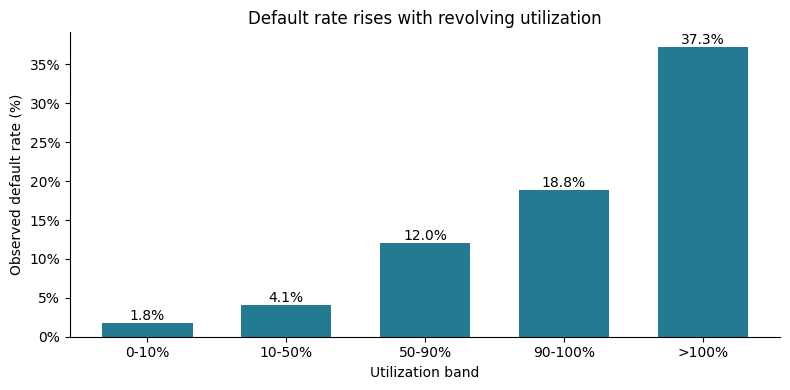

In [16]:
fig, ax = plt.subplots(figsize=(8, 4))
risk_plot(ax, util_risk, "Default rate rises with revolving utilization",
          "Utilization band")
fig.tight_layout()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

The observed default rate rises with revolving utilization from 1.8% in the 0–10% band 18.8% in the higher bands up to 100%. That is an increase of about 17 percentage points, or roughly 10 times, before reaching the >100% band. This shows that the pattern is not driven solely by extreme utilization values. These results describe an association in this dataset.

In [17]:
bins = [-np.inf, .1, .5, .9, 1, np.inf]
labels = ["0-10%", "10-50%", "50-90%", "90-100%", ">100%"]

data["UtilizationGroup"] = pd.cut(
    data["RevolvingUtilizationOfUnsecuredLines"],
    bins=bins,
    labels=labels
)

woe_table = data.groupby(
    "UtilizationGroup",
    observed=False
)[TARGET].agg(
    Total="size",
    Bad="sum"
)

woe_table["Good"] = woe_table["Total"] - woe_table["Bad"]

woe_table["Bad_Dist"] = woe_table["Bad"] / woe_table["Bad"].sum()
woe_table["Good_Dist"] = woe_table["Good"] / woe_table["Good"].sum()

woe_table["WOE"] = np.log(
    woe_table["Good_Dist"] / woe_table["Bad_Dist"]
)

woe_table["IV"] = (
    woe_table["Good_Dist"] - woe_table["Bad_Dist"]
) * woe_table["WOE"]

IV = woe_table["IV"].sum()

display(woe_table)
print("IV =", IV)

,Total,Bad,Good,Bad_Dist,Good_Dist,WOE,IV
UtilizationGroup,,,,,,,
0-10%,64390,1165,63225,0.117939,0.452150,1.343847,0.449128
10-50%,44304,1821,42483,0.184349,0.303815,0.499587,0.059683
50-90%,21219,2553,18666,0.258453,0.133489,-0.660697,0.082564
90-100%,16477,3102,13375,0.314031,0.095650,-1.188791,0.259609
>100%,3320,1237,2083,0.125228,0.014896,-2.129012,0.234897


IV = 1.0858810233161003


This value indicates that utilization, with this binning, has a strong signal for distinguishing defaults from non-defaults. Positive WOE values in the lower utilization bands mean those bands are relatively more common among non-defaults, and negative WOE values in the higher bands mean they are relatively more common among defaults.

**BUT, WAIT A MINUTE!!! This IV is TOOOOO HIGH!**

Let's check if it is because of a data leakage or not!

In [18]:
from sklearn.model_selection import train_test_split

FEATURE = "RevolvingUtilizationOfUnsecuredLines"
bins = [-np.inf, .1, .5, .9, 1, np.inf]
labels = ["0-10%", "10-50%", "50-90%", "90-100%", ">100%"]

iv_data = data.drop(columns=["NumberOfDefault"], errors="ignore")[
    [FEATURE, TARGET]
].dropna()

train, test = train_test_split(
    iv_data,
    test_size=0.30,
    random_state=42,
    stratify=iv_data[TARGET]
)


def calculate_iv(part):
    groups = pd.cut(part[FEATURE], bins=bins, labels=labels)
    table = pd.crosstab(groups, part[TARGET]).reindex(
        index=labels, columns=[0, 1], fill_value=0
    )
    table.columns = ["Good", "Bad"]

    good_dist = table["Good"] / table["Good"].sum()
    bad_dist = table["Bad"] / table["Bad"].sum()

    table["Default Rate %"] = (
        100 * table["Bad"] / (table["Good"] + table["Bad"])
    )
    table["IV"] = (good_dist - bad_dist) * np.log(good_dist / bad_dist)

    return table, table["IV"].sum()


for name, part in [("Train", train), ("Test", test)]:
    table, iv = calculate_iv(part)
    print(f"{name} IV = {iv:.3f}")
    display(table[["Good", "Bad", "Default Rate %", "IV"]].round(3))

Train IV = 1.099


,Good,Bad,Default Rate %,IV
RevolvingUtilizationOfUnsecuredLines,,,,
0-10%,44325,808,1.790,0.455
10-50%,29710,1263,4.078,0.061
50-90%,12993,1826,12.322,0.090
90-100%,9426,2140,18.503,0.249
>100%,1428,878,38.075,0.243


Test IV = 1.058


,Good,Bad,Default Rate %,IV
RevolvingUtilizationOfUnsecuredLines,,,,
0-10%,18900,357,1.854,0.435
10-50%,12773,558,4.186,0.056
50-90%,5673,727,11.359,0.066
90-100%,3949,962,19.589,0.285
>100%,655,359,35.404,0.216


As the IV values are similar in the train and test sets, and every group contains both Good and Bad cases, that is a good evidence that this feature is not an artifact of calculating IV on the same data or of a group that directly mirrors the target. But we still need to check the temporal leakage to confirm that utilization was recorded before the target period.

## 2. NumberOfTimes90DaysLate

In [19]:
summary = data.groupby(TARGET)["NumberOfTimes90DaysLate"].agg(
    count="count",
    median="median",
    mean="mean"
)

summary.index = summary.index.map({
    0: "Non-default",
    1: "Default"
})

summary = summary.reindex(["Default", "Non-default"])
display(summary.round({"median": 3, "mean": 3}))

,count,median,mean
SeriousDlqin,,,
Default,9878,0.0,0.665
Non-default,139832,0.0,0.050


Both class medians are zero that median alone hides the difference between groups.

In [20]:
late_groups = pd.cut(data["NumberOfTimes90DaysLate"], [-.5, .5, 1.5, 2.5, np.inf],
                     labels=["0", "1", "2", "3+"])
late_risk = risk_table(data, late_groups)
display(late_risk)

late_class_share = pd.crosstab(
    late_groups, data[TARGET], normalize="columns").mul(100)
display(late_class_share.rename(columns=CLASS_LABELS))

,records,defaults,default_rate_pct
group,,,
0,141642,6553,4.626453
1,5243,1765,33.663933
2,1554,776,49.935650
3+,1271,784,61.683714


SeriousDlqin,Non-default (0),Default (1)
NumberOfTimes90DaysLate,,
0,96.608073,66.339340
1,2.487270,17.867989
2,0.556382,7.855841
3+,0.348275,7.936829


The detailed table shows an increasing rate across 0, 1, 2 and 3+ events.

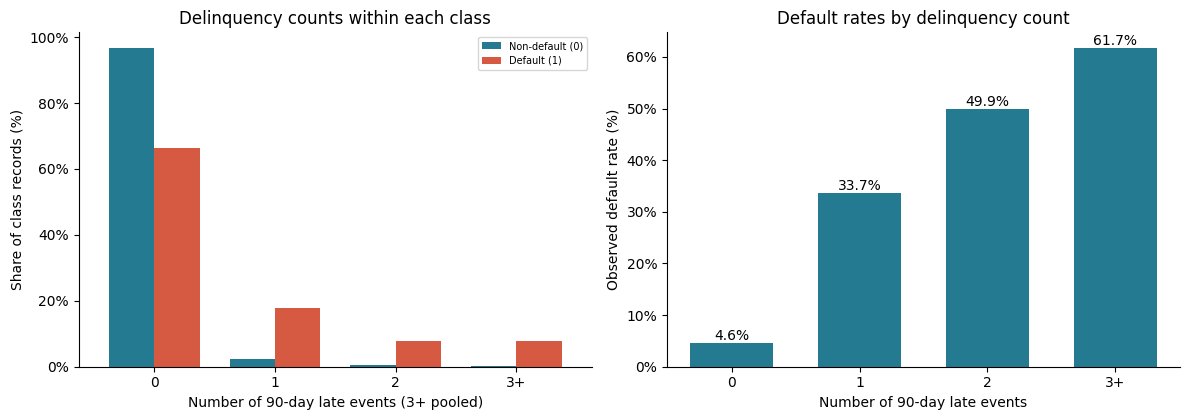

In [21]:
COLORS = {0: "#247B91", 1: "#D65A42"}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
late_class_share.rename(columns=CLASS_LABELS).plot.bar(
    ax=axes[0], color=[COLORS[0], COLORS[1]], rot=0, width=.75)

axes[0].set(title="Delinquency counts within each class",
            xlabel="Number of 90-day late events (3+ pooled)",
            ylabel="Share of class records (%)")
axes[0].yaxis.set_major_formatter(PercentFormatter(100, decimals=0))
axes[0].legend(fontsize=7)
axes[0].spines["top"].set_visible(False)
axes[1].spines["top"].set_visible(False)
axes[0].spines["right"].set_visible(False)
axes[1].spines["right"].set_visible(False)

risk_plot(axes[1], late_risk, "Default rates by delinquency count",
          "Number of 90-day late events")
fig.tight_layout()

The default rate rises as the number of 90-day late payments increases. For example, the default rate in the “3 or more” group is about **13 times** the rate in the group with no late payments.

The table also highlights an important point. Although customers with late payments have higher default rates, **66% of all defaulters had no recorded 90-day late payments**. So this feature alone cannot identify every default.

In overall, the number of 90-day late payments has a **strong statistical association** with default in this dataset, but the association also does not prove that late payments cause default.

In [22]:
feature = "NumberOfTimes90DaysLate"

bins = [-.5, .5, 1.5, 2.5, np.inf]
labels = ["0", "1", "2", "3+"]

data["LateGroup"] = pd.cut(
    data[feature],
    bins=bins,
    labels=labels
)

woe_table = data.groupby(
    "LateGroup",
    observed=False
)[TARGET].agg(
    Total="size",
    Bad="sum"
)

woe_table["Good"] = woe_table["Total"] - woe_table["Bad"]

woe_table["Bad_Dist"] = (
    woe_table["Bad"] / woe_table["Bad"].sum()
)

woe_table["Good_Dist"] = (
    woe_table["Good"] / woe_table["Good"].sum()
)

woe_table["WOE"] = np.log(
    woe_table["Good_Dist"] / woe_table["Bad_Dist"]
)

woe_table["IV"] = (
    woe_table["Good_Dist"] - woe_table["Bad_Dist"]
) * woe_table["WOE"]

IV = woe_table["IV"].sum()

display(woe_table)
print("IV =", IV)

,Total,Bad,Good,Bad_Dist,Good_Dist,WOE,IV
LateGroup,,,,,,,
0,141642,6553,135089,0.663393,0.966081,0.375879,0.113774
1,5243,1765,3478,0.178680,0.024873,-1.971825,0.303281
2,1554,776,778,0.078558,0.005564,-2.647558,0.193257
3+,1271,784,487,0.079368,0.003483,-3.126277,0.237239


IV = 0.8475513094947831


For groups with one or more late payments, WOE is negative and becomes more negative as the number of late payments increases. This means these groups are relatively more associated with defaults. This is consistent with the default rates we saw earlier.

## 3. Age

In [23]:
age_df = data.loc[data["age"].notnull()].copy()
age_groups = pd.cut(age_df["age"], [18, 30, 40, 50, 60, 70, 101], right=False,
                    labels=["18-29", "30-39", "40-49", "50-59", "60-69", "70-100"])
age_risk = risk_table(age_df, age_groups)
age_risk

,records,defaults,default_rate_pct
group,,,
18-29,8677,973,11.213553
30-39,23139,2308,9.974502
40-49,34341,2855,8.313678
50-59,35264,2254,6.391788
60-69,28891,1040,3.599737
70-100,19398,448,2.309516


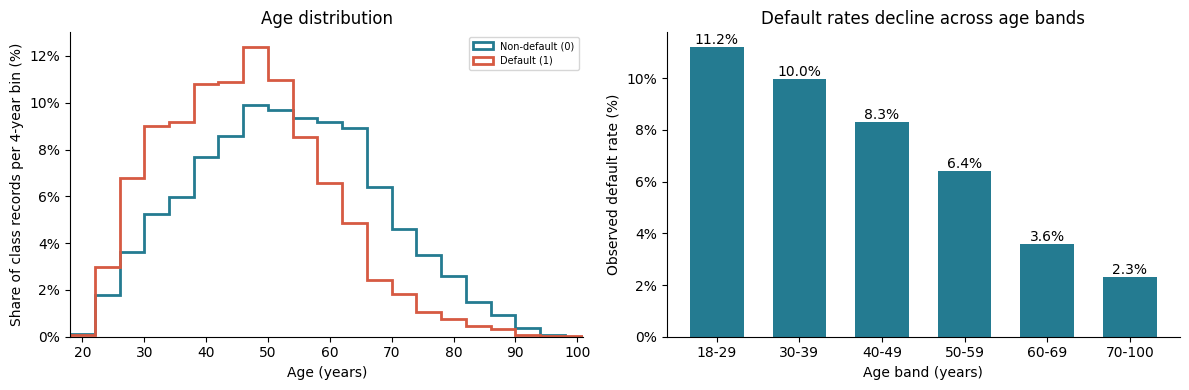

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for label in [0, 1]:
    ages = age_df.loc[age_df[TARGET].eq(label), "age"]
    axes[0].hist(ages, bins=np.arange(18, 104, 4),
                 weights=np.full(len(ages), 100/len(ages)), histtype="step",
                 color=COLORS[label], label=CLASS_LABELS[label], linewidth=2)

axes[0].set(title="Age distribution", xlabel="Age (years)",
            ylabel="Share of class records per 4-year bin (%)", xlim=(18, 101))
axes[0].yaxis.set_major_formatter(PercentFormatter(100, decimals=0))
axes[0].legend(fontsize=7)
axes[0].spines["top"].set_visible(False)
axes[1].spines["top"].set_visible(False)
axes[0].spines["right"].set_visible(False)
axes[1].spines["right"].set_visible(False)

risk_plot(axes[1], age_risk,
          "Default rates decline across age bands", "Age band (years)")
fig.tight_layout()

The age distribution of defaulters is generally shifted toward younger ages. Their median age is **46**, compared with **52** for non-defaulters. However, the two distributions overlap, so age alone does not separate the groups.

The default rate declines across the age bands in this dataset. The rate for customers aged 18-29 is about **4.9 times** the rate for those aged 70-100. Overall, younger age is associated with a higher default rate, but this observed relationship does not prove that age causes default, and age alone is not enough to predict it.

In [25]:
feature = "age"

bins = [18, 30, 40, 50, 60, 70, 101]
labels = ["18-29", "30-39", "40-49", "50-59", "60-69", "70-100"]

age_data = data.loc[data[feature].between(18, 100)].copy()

age_data["AgeGroup"] = pd.cut(
    age_data[feature],
    bins=bins,
    labels=labels,
    right=False
)

woe_table = age_data.groupby(
    "AgeGroup",
    observed=False
)[TARGET].agg(
    Total="size",
    Bad="sum"
)

woe_table["Good"] = woe_table["Total"] - woe_table["Bad"]

woe_table["Bad_Dist"] = (
    woe_table["Bad"] / woe_table["Bad"].sum()
)

woe_table["Good_Dist"] = (
    woe_table["Good"] / woe_table["Good"].sum()
)

woe_table["WOE"] = np.log(
    woe_table["Good_Dist"] / woe_table["Bad_Dist"]
)

woe_table["IV"] = (
    woe_table["Good_Dist"] - woe_table["Bad_Dist"]
) * woe_table["WOE"]

IV = woe_table["IV"].sum()

display(woe_table)
print("IV =", IV)

,Total,Bad,Good,Bad_Dist,Good_Dist,WOE,IV
AgeGroup,,,,,,,
18-29,8677,973,7704,0.098502,0.055095,-0.581021,0.025220
30-39,23139,2308,20831,0.233651,0.148972,-0.450071,0.038112
40-49,34341,2855,31486,0.289026,0.225170,-0.249660,0.015942
50-59,35264,2254,33010,0.228184,0.236069,0.033972,0.000268
60-69,28891,1040,27851,0.105284,0.199175,0.637517,0.059857
70-100,19398,448,18950,0.045353,0.135520,1.094634,0.098699


IV = 0.23809795275241136


The results show that younger age groups are relatively more represented among defaulters, while older age groups are relatively more represented among non-defaulters.

## Additional analysis

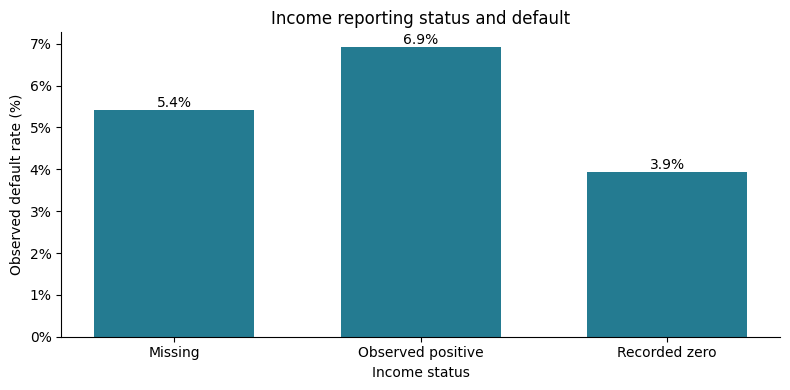

In [26]:
income_status = pd.Series(
    "Observed positive", index=data.index, name="Income status")
income_status.loc[data["MonthlyIncome"].eq(0)] = "Recorded zero"
income_status.loc[data["MonthlyIncome"].isna()] = "Missing"
income_risk = risk_table(data, income_status)

fig, ax = plt.subplots(figsize=(8, 4))
risk_plot(
    ax,
    income_risk,
    "Income reporting status and default",
    "Income status"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()

Customers with missing monthly income have a **lower default rate** than those who income is recorded. So missing income should not automatically be treated as a sign of greater financial distress. It might be because of the data-collection process.

If we replace missing values with the median income, the distinction between customers with missing income and the rest may be hidden.

## Final insights

I would start with `RevolvingUtilizationOfUnsecuredLines`, because 1) its median is
0.830 for defaults versus 0.133 for non-defaults, 2) it
signals limited credit headroom, 3) it is associated with a higher default rate. I would add `NumberOfTimes90DaysLate`, because
the default rate is much higher among customers with a recorded severe delay. My third choice is
`age`, because the default-class median is 46 versus 52 years and the age bands
show a consistent downward trend.

The following figure summarizes the three selected features.

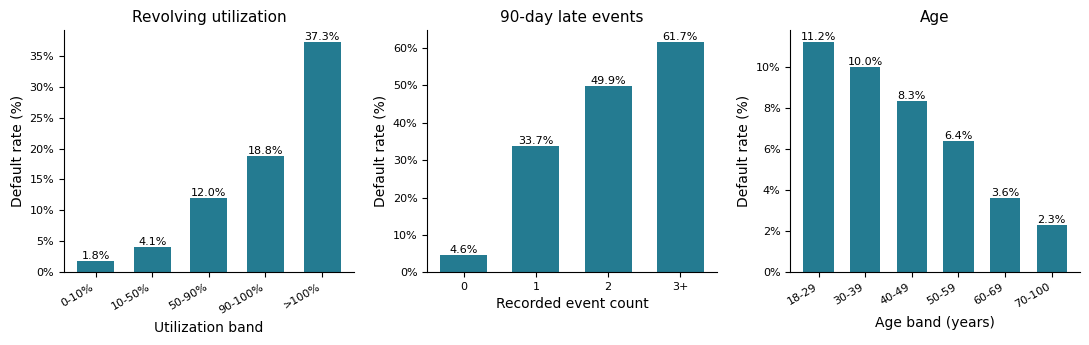

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.55))
risk_plot(axes[0], util_risk, "Revolving utilization", "Utilization band")
risk_plot(axes[1], late_risk, "90-day late events", "Recorded event count")
risk_plot(axes[2], age_risk, "Age", "Age band (years)")
axes[0].set_xticks(np.arange(5), ["0-10%", "10-50%", "50-90%", "90-100%", ">100%"],
                   rotation=30, ha="right")
axes[2].set_xticks(np.arange(6), ["18-29", "30-39", "40-49", "50-59", "60-69", "70-100"],
                   rotation=30, ha="right")

axes[0].spines["top"].set_visible(False)
axes[1].spines["top"].set_visible(False)
axes[2].spines["top"].set_visible(False)
axes[0].spines["right"].set_visible(False)
axes[1].spines["right"].set_visible(False)
axes[2].spines["right"].set_visible(False)

for ax in axes:
    ax.set_title(ax.get_title(), fontsize=11)
    ax.set_xlabel(ax.get_xlabel(), fontsize=10)
    ax.set_ylabel("Default rate (%)", fontsize=10)
    ax.tick_params(axis="both", labelsize=8)
    for label in ax.texts:
        label.set_fontsize(8)
fig.tight_layout(w_pad=1.4)